# Lab 04 — n-Queens: tìm kiếm cục bộ

Hoàn thành **bài 5–8 trong PDF**, **Task 1–6** và **Advanced task** của notebook n-Queens.

**Team: Quý - Phúc - Tri - Khoa**
**Công cụ hỗ trợ:** OpenAI Codex hỗ trợ cài đặt, kiểm thử và diễn giải; người nộp cần tự kiểm tra,
hiểu lời giải và xác nhận trách nhiệm theo yêu cầu của học phần.

Chạy **Restart Kernel → Run All** để tạo lại toàn bộ hình/bảng, CSV và báo cáo tổng hợp.
Không dùng thư viện giải sẵn. Các seed và điều kiện dừng được ghi rõ bên dưới.

In [1]:
%matplotlib inline
from collections import Counter
from itertools import combinations, product
from math import ceil, exp, log
from pathlib import Path
from time import perf_counter
import json
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
import matplotlib
print('Môi trường:', platform.system(), platform.machine(), '| Python', platform.python_version())
display(pd.DataFrame({'thư viện': ['NumPy', 'pandas', 'Matplotlib'],
                      'phiên bản': [np.__version__, pd.__version__, matplotlib.__version__]}))
print('Seed minh họa = 1234')

Môi trường: Windows AMD64 | Python 3.10.11


,thư viện,phiên bản
0,NumPy,2.2.6
1,pandas,2.3.3
2,Matplotlib,3.10.7


Seed minh họa = 1234


## Bài 5. Biểu diễn bàn cờ và hàm mục tiêu

Trạng thái `board[c] = r` đặt một quân hậu ở hàng $r$, cột $c$, chỉ số từ 0.
Mỗi cột có đúng một hậu nên không cần tính xung đột cột. Hàm mục tiêu:

$$h(q)=\sum_{0\le i<j<n}\mathbf1[q_i=q_j\;\lor\;|q_i-q_j|=|i-j|].$$

Mỗi cặp được tính một lần. Cách tính nhanh: đếm số hậu trên từng hàng,
đường chéo $c+r$, đường chéo $c-r$ rồi cộng $\binom{k}{2}$ cho từng bộ đếm.
Một cặp hậu ở hai cột khác nhau không đồng thời cùng hàng và cùng đường chéo nên không bị đếm trùng.
Do từng số hạng không âm, **h = 0 khi và chỉ khi không có cặp hậu nào tấn công nhau**.
Bài toán có nghiệm khi $n=1$ hoặc $n\ge4$; $n=2,3$ vô nghiệm, nên các thí nghiệm dùng $n\ge4$.

board = [3, 0, 0, 0] ; h = 4
board = [0, 1, 1, 5, 3, 0, 0, 0] ; h = 10
board = [1, 3, 0, 2] ; h = 0


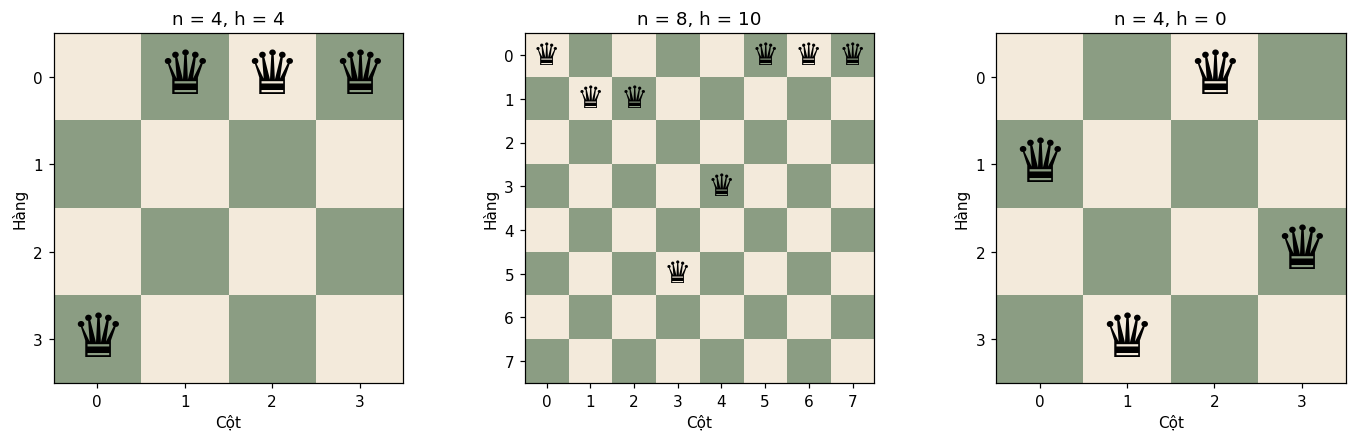

Đạt 256 đối chiếu hàm mục tiêu với định nghĩa đếm từng cặp.


In [2]:
def random_board(n, rng=None):
    rng = rng or random.Random()
    return [rng.randrange(n) for _ in range(n)]


def conflicts(board):
    n = len(board)
    rows, diag1, diag2 = [0] * n, [0] * (2 * n - 1), [0] * (2 * n - 1)
    for col, row in enumerate(board):
        rows[row] += 1
        diag1[col + row] += 1
        diag2[col - row + n - 1] += 1
    return sum(count * (count - 1) // 2 for count in rows + diag1 + diag2)


def pairwise_conflicts(board):
    return sum(board[i] == board[j] or abs(board[i] - board[j]) == j - i
               for i, j in combinations(range(len(board)), 2))


def show_board(board, ax=None, title=''):
    n = len(board)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(np.indices((n, n)).sum(axis=0) % 2,
              cmap=ListedColormap(['#f3eadb', '#8b9d83']), vmin=0, vmax=1)
    for col, row in enumerate(board):
        ax.text(col, row, '\u265b', fontsize=max(12, 160 // n), ha='center', va='center')
    ax.set(xticks=range(n), yticks=range(n), xlabel='Cột', ylabel='Hàng',
           title=title or f'n = {n}, h = {conflicts(board)}')
    return ax


rng_demo = random.Random(1234)
boards = [random_board(4, rng_demo), random_board(8, rng_demo), [1, 3, 0, 2]]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, board in zip(axes, boards):
    show_board(board, ax)
    print('board =', board, '; h =', conflicts(board))
plt.tight_layout()
plt.show()
assert conflicts([1, 3, 0, 2]) == 0
assert conflicts([0, 0, 0, 0]) == 6
for board in product(range(4), repeat=4):
    assert conflicts(board) == pairwise_conflicts(board)
print('Đạt 256 đối chiếu hàm mục tiêu với định nghĩa đếm từng cặp.')

## Bài 6 / Task 1–3. Ba biến thể Hill Climbing

Nước đi cơ bản chuyển một hậu sang **hàng khác** trong cùng cột; có $M=n(n-1)$ nước đi.
Ta cực tiểu hóa xung đột: “uphill” trong cách nói tối đa hóa chất lượng tương đương **giảm h**.
Cả ba biến thể chỉ nhận cải thiện nghiêm ngặt, không nhận bước ngang.

- **Steepest-ascent:** đánh giá đủ $M$ nước đi, chọn ngẫu nhiên trong các nước có h thấp nhất;
  dừng khi không có nước cải thiện.
- **Inefficient Stochastic:** cũng đánh giá đủ $M$ nước đi, nhưng chọn ngẫu nhiên trong **mọi** nước cải thiện.
- **Efficient Stochastic / First-choice:** mỗi vòng chỉ lấy một nước đi ngẫu nhiên; nếu h giảm thì nhận.

Với first-choice, dừng sau $x=\lceil M\ln(M/\varepsilon)\rceil$ lần liên tiếp không cải thiện,
$\varepsilon=0{,}01$. Ở một trạng thái cố định, xác suất bỏ sót một nước sau x lần lấy mẫu là
$(1-1/M)^x\le e^{-x/M}$; theo union bound, xác suất chưa thăm hết $M$ nước không quá
$M e^{-x/M}\le\varepsilon$. Sau một cải thiện phải **đặt lại bộ đếm**, vì trạng thái đã đổi.
Đây chỉ là bảo đảm xác suất tại từng trạng thái, không phải chứng minh cực tiểu hay bảo đảm cho toàn bộ quá trình.
Thêm giới hạn tổng 10.000 đề xuất để có điểm dừng hữu hạn; `budget` khác với `stalled`.

`evaluations` đếm một lần tính h ban đầu và mỗi h của ứng viên; `iterations` đếm số lượt
quét toàn bộ hoặc số đề xuất đơn; `moves` đếm số lần nhận thay đổi. Các đơn vị này khác COUNT của CSP.

In [3]:
def all_neighbors(board):
    for col in range(len(board)):
        for row in range(len(board)):
            if row != board[col]:
                candidate = list(board)
                candidate[col] = row
                yield candidate


def propose(board, rng, operator='single'):
    n = len(board)
    candidate = list(board)

    def different_row(col):
        value = rng.randrange(n - 1)
        return value + (value >= board[col])

    if operator == 'single':
        col = rng.randrange(n)
        candidate[col] = different_row(col)
    elif operator == 'single_step':
        col = rng.randrange(n)
        candidate[col] = rng.choice([r for r in [board[col] - 1, board[col] + 1] if 0 <= r < n])
    elif operator == 'swap':
        i, j = rng.sample(range(n), 2)
        candidate[i], candidate[j] = candidate[j], candidate[i]
    elif operator == 'dual':
        for col in rng.sample(range(n), 2):
            candidate[col] = different_row(col)
    elif operator == 'adaptive':
        # 40% lấy đều toàn bộ nước đi; 60% tập trung hậu có nhiều xung đột nhất.
        if rng.random() < 0.4:
            return propose(board, rng, 'single')
        badness = [sum(col != j and (board[col] == board[j] or
                       abs(board[col] - board[j]) == abs(col - j)) for j in range(n))
                   for col in range(n)]
        worst = max(badness)
        col = rng.choice([i for i, score in enumerate(badness) if score == worst])
        candidate[col] = different_row(col)
    else:
        raise ValueError(operator)
    return candidate


def patience_bound(n, operator='single', epsilon=0.01):
    m = n * (n - 1)
    if operator == 'single_step':
        m = 2 * n  # Cận bảo thủ: mỗi nước đi có xác suất ít nhất 1/(2n).
    elif operator == 'swap':
        m = n * (n - 1) // 2
    elif operator == 'dual':
        m = n * (n - 1) // 2 * (n - 1) ** 2
    factor = 1 / 0.4 if operator == 'adaptive' else 1
    return ceil(factor * m * log(m / epsilon))


def hill_climb(initial, variant='steepest', seed=0, max_iterations=10_000,
               operator='single', record_history=False):
    started = perf_counter()
    rng = random.Random(seed)
    board = list(initial)
    h = conflicts(board)
    evaluations, iterations, moves, stale = 1, 0, 0, 0
    history = [h] if record_history else []
    patience = patience_bound(len(board), operator)
    status, stop_reason = 'budget', 'proposal_limit'
    for _ in range(max_iterations):
        if h == 0:
            status, stop_reason = 'solved', 'zero_conflicts'
            break
        iterations += 1
        if variant in ['steepest', 'inefficient']:
            scored = [(conflicts(candidate), candidate) for candidate in all_neighbors(board)]
            evaluations += len(scored)
            best_h = min(score for score, _ in scored)
            if best_h >= h:
                status = 'local_optimum'
                stop_reason = 'plateau' if best_h == h else 'strict_local_minimum'
                if record_history:
                    history.append(h)
                break
            if variant == 'steepest':
                choices = [(score, candidate) for score, candidate in scored if score == best_h]
            else:
                choices = [(score, candidate) for score, candidate in scored if score < h]
            h, board = rng.choice(choices)
            moves += 1
        elif variant == 'efficient':
            candidate = propose(board, rng, operator)
            new_h = conflicts(candidate)
            evaluations += 1
            if new_h < h:
                board, h = candidate, new_h
                moves += 1
                stale = 0
            else:
                stale += 1
        else:
            raise ValueError(variant)
        if record_history:
            history.append(h)
        if h == 0:
            status, stop_reason = 'solved', 'zero_conflicts'
            break
        if variant == 'efficient' and stale >= patience:
            status, stop_reason = 'stalled', 'probabilistic_stopping'
            break
    return {'board': list(board), 'h': h, 'final_h': h, 'status': status,
            'stop_reason': stop_reason, 'evaluations': evaluations, 'iterations': iterations,
            'moves': moves, 'restarts': 0, 'patience': patience,
            'seconds': perf_counter() - started, 'history': history}


hc_variants = {'Steepest HC': 'steepest', 'Inefficient Stochastic HC': 'inefficient',
               'Efficient Stochastic HC': 'efficient'}
demo8 = random_board(8, random.Random(1234))
hc_demo = {name: hill_climb(demo8, variant, seed=2026, record_history=True)
           for name, variant in hc_variants.items()}
display(pd.DataFrame([{'algorithm': name, **{key: r[key] for key in
    ['h', 'status', 'stop_reason', 'iterations', 'evaluations', 'moves', 'patience']}}
    for name, r in hc_demo.items()]))
print('Patience cho n=4:', patience_bound(4), '; n=8:', patience_bound(8))

,algorithm,h,status,stop_reason,iterations,evaluations,moves,patience
0,Steepest HC,0,solved,zero_conflicts,4,225,4,484
1,Inefficient Stochastic HC,1,local_optimum,plateau,10,561,9,484
2,Efficient Stochastic HC,1,stalled,probabilistic_stopping,526,527,9,484


Patience cho n=4: 86 ; n=8: 484


**Vì sao có thể kẹt:** tại cực tiểu cục bộ, mọi nước đi đơn đều có h lớn hơn; ở plateau,
một số nước giữ h nhưng không có nước giảm h. Ba HC đang xét chỉ chấp nhận giảm h, nên dừng
hoặc lấy mẫu nhiều lần mà không thoát được. Hai biến thể quét đầy đủ xác nhận điều này qua
toàn bộ láng giềng. First-choice chỉ báo dừng theo xác suất, không được gọi là đã chứng minh cực tiểu.

## Bài 7 / Task 4. Random Restart

Chạy một trong ba HC trên bàn cờ ban đầu. Nếu chưa giải được, sinh bàn cờ mới và chạy lại,
tối đa **100 restart**, tức tối đa 101 lần khởi tạo. Dừng ngay khi h = 0; nếu hết ngân sách thì
trả bàn cờ tốt nhất tìm được. Cộng tất cả số lần đánh giá, vòng lặp, bước nhận và thời gian.
Chi phí restart không được chỉ tính trên lượt cuối cùng.

In [4]:
def random_restart(initial, variant='steepest', seed=0, max_restarts=100,
                   record_history=False):
    started = perf_counter()
    rng = random.Random(seed)
    best = None
    evaluations = iterations = moves = 0
    history, restart_at = [], []
    for restart in range(max_restarts + 1):
        board = list(initial) if restart == 0 else random_board(len(initial), rng)
        result = hill_climb(board, variant, seed=rng.randrange(2**32),
                            record_history=record_history)
        evaluations += result['evaluations']
        iterations += result['iterations']
        moves += result['moves']
        if best is None or result['h'] < best['h']:
            best = result
        if record_history:
            if restart:
                restart_at.append(len(history))
            history.extend(result['history'])
        if result['h'] == 0:
            break
    return {'board': list(best['board']), 'h': best['h'], 'final_h': result['h'],
            'status': 'solved' if best['h'] == 0 else 'restart_limit',
            'evaluations': evaluations, 'iterations': iterations, 'moves': moves,
            'restarts': restart, 'starts': restart + 1, 'seconds': perf_counter() - started,
            'history': history, 'restart_at': restart_at}


rr_demo = {f'RR {name}': random_restart(demo8, variant, seed=2026, record_history=True)
           for name, variant in hc_variants.items()}
display(pd.DataFrame([{'algorithm': name, **{key: r[key] for key in
    ['h', 'status', 'starts', 'restarts', 'evaluations', 'iterations', 'moves']}}
    for name, r in rr_demo.items()]))

,algorithm,h,status,starts,restarts,evaluations,iterations,moves
0,RR Steepest HC,0,solved,1,0,281,5,5
1,RR Inefficient Stochastic HC,0,solved,7,6,2247,40,34
2,RR Efficient Stochastic HC,0,solved,8,7,3996,3988,42


## Bài 7 / Task 5. Simulated Annealing và lịch nhiệt

Sinh một nước đi ngẫu nhiên, đặt $\Delta=h(q')-h(q)$: nhận nếu $\Delta\le0$;
nếu $\Delta>0$, nhận với xác suất $e^{-\Delta/T}$. Khi T cao có thể thoát vùng xấu;
T thấp làm hành vi gần với tìm kiếm tham lam. Luôn giữ riêng **bàn cờ tốt nhất** và **trạng thái cuối**.

Tham khảo công thức chấp nhận và vai trò lịch nhiệt trong
[giáo trình CS188 của UC Berkeley](https://inst.eecs.berkeley.edu/~cs188/textbook/csp/local-search.html).
Các thông số dưới đây là lựa chọn thực nghiệm của bài làm, không phải thông số tối ưu được nguồn bảo đảm.

Cùng 5.000 đề xuất tối đa, $T_0=2$, $T_{end}=0{,}01$, so sánh:

- **Geometric:** $T_t=T_0(T_{end}/T_0)^{t/(K-1)}$.
- **Inverse:** $T_t=T_0/[1+\beta t]$, $\beta=(T_0/T_{end}-1)/(K-1)$.

Hai lịch có cùng điểm đầu/cuối; inverse giảm nhanh hơn lúc đầu. Dừng sớm khi tìm được h = 0;
nếu chưa giải được sau K đề xuất, báo hết ngân sách. Không khẳng định hội tụ chắc chắn với K hữu hạn.

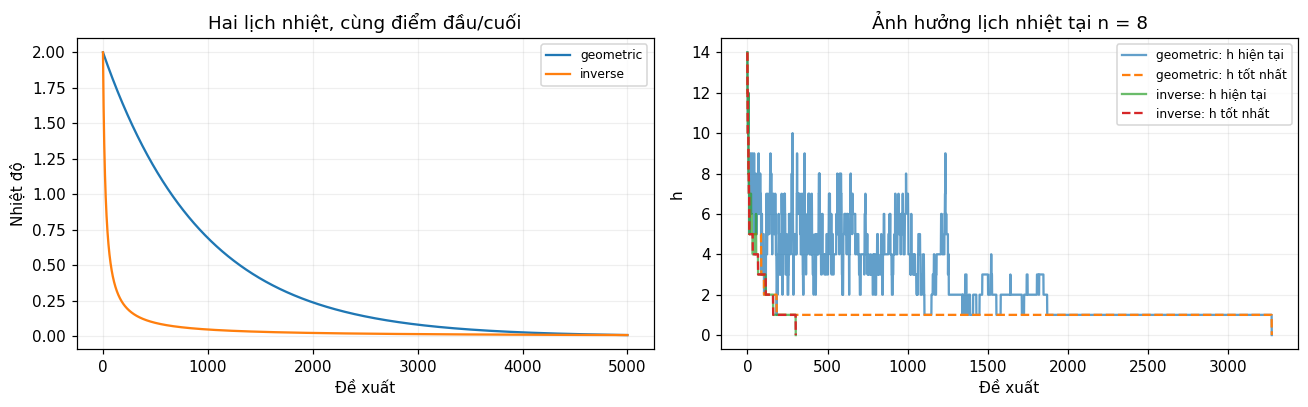

,schedule,h,final_h,status,iterations,evaluations,worsening_moves,sideways_moves
0,SA geometric,0,0,solved,3272,3273,204,425
1,SA inverse,0,0,solved,302,303,7,40


In [5]:
def temperature(t, schedule, max_steps, t0=2.0, tend=0.01):
    fraction = t / max(1, max_steps - 1)
    if schedule == 'geometric':
        return t0 * (tend / t0) ** fraction
    if schedule == 'inverse':
        return t0 / (1 + (t0 / tend - 1) * fraction)
    raise ValueError(schedule)


def simulated_annealing(initial, schedule='geometric', seed=0,
                         max_steps=5000, record_history=False):
    started = perf_counter()
    rng = random.Random(seed)
    board = list(initial)
    h = best_h = conflicts(board)
    best_board = list(board)
    evaluations, iterations, moves, worse, sideways = 1, 0, 0, 0, 0
    history = [h] if record_history else []
    best_history = [h] if record_history else []
    for t in range(max_steps):
        if h == 0:
            break
        iterations += 1
        candidate = propose(board, rng)
        new_h = conflicts(candidate)
        evaluations += 1
        delta = new_h - h
        temp = temperature(t, schedule, max_steps)
        if delta <= 0 or rng.random() < exp(-delta / temp):
            board, h = candidate, new_h
            moves += 1
            worse += int(delta > 0)
            sideways += int(delta == 0)
        if h < best_h:
            best_board, best_h = list(board), h
        if record_history:
            history.append(h)
            best_history.append(best_h)
    return {'board': best_board, 'h': best_h, 'final_board': board, 'final_h': h,
            'status': 'solved' if best_h == 0 else 'budget',
            'evaluations': evaluations, 'iterations': iterations, 'moves': moves,
            'worsening_moves': worse, 'sideways_moves': sideways, 'restarts': 0,
            'seconds': perf_counter() - started, 'history': history, 'best_history': best_history}


sa_demo = {f'SA {schedule}': simulated_annealing(demo8, schedule, seed=2026, record_history=True)
           for schedule in ['geometric', 'inverse']}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for schedule in ['geometric', 'inverse']:
    result = sa_demo[f'SA {schedule}']
    axes[0].plot([temperature(t, schedule, 5000) for t in range(5000)], label=schedule)
    axes[1].plot(result['history'], label=f'{schedule}: h hiện tại', alpha=0.7)
    axes[1].plot(result['best_history'], '--', label=f'{schedule}: h tốt nhất')
axes[0].set(xlabel='Đề xuất', ylabel='Nhiệt độ', title='Hai lịch nhiệt, cùng điểm đầu/cuối')
axes[1].set(xlabel='Đề xuất', ylabel='h', title='Ảnh hưởng lịch nhiệt tại n = 8')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'schedule': name, **{key: r[key] for key in
    ['h', 'final_h', 'status', 'iterations', 'evaluations', 'worsening_moves', 'sideways_moves']}}
    for name, r in sa_demo.items()]))

### Kiểm chứng trước khi đo

Kiểm tra nghiệm biết trước; HC đơn điệu; nghiệm trả về đúng h; hai thuật toán quét đủ thực sự
dừng khi không còn cải thiện; first-choice có đúng số lần đánh giá; restart tôn trọng giới hạn;
SA lưu h tốt nhất không lớn hơn h cuối và lịch nhiệt giảm đúng điểm đầu/cuối.

In [6]:
for variant in hc_variants.values():
    solved = hill_climb([1, 3, 0, 2], variant)
    assert solved['h'] == 0 and solved['evaluations'] == 1 and solved['moves'] == 0
    result = hill_climb([0, 0, 0, 0], variant, seed=7, record_history=True)
    assert result['h'] == conflicts(result['board'])
    assert all(a >= b for a, b in zip(result['history'], result['history'][1:]))
    if variant != 'efficient':
        assert result['evaluations'] == 1 + result['iterations'] * 12
        if result['status'] == 'local_optimum':
            assert all(conflicts(b) >= result['h'] for b in all_neighbors(result['board']))
    else:
        assert result['evaluations'] == 1 + result['iterations']
    rr = random_restart([0, 0, 0, 0], variant, seed=7, max_restarts=0)
    assert rr['restarts'] == 0 and rr['starts'] == 1
    assert rr['h'] == conflicts(rr['board'])

for schedule in ['geometric', 'inverse']:
    assert np.isclose(temperature(0, schedule, 5000), 2.0)
    assert np.isclose(temperature(4999, schedule, 5000), 0.01)
    temperatures = [temperature(t, schedule, 5000) for t in range(5000)]
    assert all(a >= b for a, b in zip(temperatures, temperatures[1:]))
    result = simulated_annealing(demo8, schedule, seed=7, max_steps=200, record_history=True)
    assert result['h'] == conflicts(result['board']) <= result['final_h']
    assert result['final_h'] == conflicts(result['final_board'])
    assert result['evaluations'] == result['iterations'] + 1
    assert result['h'] == min(result['history'])
    assert all(a >= b for a, b in zip(result['best_history'], result['best_history'][1:]))
for operator in ['single', 'single_step', 'swap', 'dual', 'adaptive']:
    for seed in range(20):
        candidate = propose(demo8, random.Random(seed), operator)
        assert len(candidate) == 8 and all(0 <= row < 8 for row in candidate)
        changed = [i for i in range(8) if candidate[i] != demo8[i]]
        if operator in ['single', 'single_step', 'adaptive']:
            assert len(changed) == 1
        if operator == 'single_step':
            assert abs(candidate[changed[0]] - demo8[changed[0]]) == 1
        if operator == 'swap':
            assert sorted(candidate) == sorted(demo8)
        if operator == 'dual':
            assert len(changed) == 2
print('Đạt kiểm thử HC, Random Restart, SA và 5 toán tử di chuyển.')

Đạt kiểm thử HC, Random Restart, SA và 5 toán tử di chuyển.


## Bài 8 / Task 6. So sánh ít nhất 100 lượt

Với mỗi $n=4,8$, sinh **100 bàn cờ khởi tạo phân biệt**, seed `4100+n`; dùng cùng tập bàn cờ
cho mọi thuật toán. Có 8 cấu hình: ba HC, ba HC có restart, hai lịch SA.
Seed tìm kiếm là hàm cố định của n và chỉ số lượt, không dùng hash phụ thuộc tiến trình.

HC quét toàn bộ dừng tại cực trị; first-choice dùng patience ở trên và tối đa 10.000 đề xuất;
RR cho tối đa 100 restart với cùng điều kiện HC; SA tối đa 5.000 đề xuất. Các ngân sách khác nhau
được báo rõ: so sánh khả năng đạt nghiệm kèm chi phí thực tế, không tuyên bố chúng có cùng ngân sách.
Thời gian tính cả khởi tạo nội bộ và các restart, không tính sinh tập bàn cờ hay vẽ.

Bảng báo cáo **h của lời giải trả về** (h tốt nhất với SA/RR), thêm `mean_final_h` để thấy trạng thái cuối,
tỷ lệ h=0, số đánh giá, vòng lặp, bước nhận và restart. Thành công chỉ khi h=0,
không gọi một trạng thái ít xung đột hơn là nghiệm hợp lệ.

In [7]:
def make_starts(n, count, seed):
    rng = random.Random(seed)
    seen, boards = set(), []
    while len(boards) < count:
        board = tuple(random_board(n, rng))
        if board not in seen:
            boards.append(list(board))
            seen.add(board)
    return boards


ALGORITHMS = {}
for name, variant in hc_variants.items():
    ALGORITHMS[name] = ('hc', variant)
for name, variant in hc_variants.items():
    ALGORITHMS[f'RR {name}'] = ('rr', variant)
for schedule in ['geometric', 'inverse']:
    ALGORITHMS[f'SA {schedule}'] = ('sa', schedule)


def solve(initial, kind, option, seed, record_history=False):
    if kind == 'hc':
        return hill_climb(initial, option, seed=seed, record_history=record_history)
    if kind == 'rr':
        return random_restart(initial, option, seed=seed, max_restarts=100,
                              record_history=record_history)
    if kind == 'sa':
        return simulated_annealing(initial, option, seed=seed, max_steps=5000,
                                   record_history=record_history)
    raise ValueError(kind)


RUNS = 100
benchmark_rows = []
initial_rows = []
for n in [4, 8]:
    initial_boards = make_starts(n, RUNS, 4100 + n)
    for trial, initial in enumerate(initial_boards):
        initial_rows.append(dict(n=n, trial=trial, board=json.dumps(initial), initial_h=conflicts(initial)))
        for name, (kind, option) in ALGORITHMS.items():
            seed = 100_000 * n + trial
            result = solve(initial, kind, option, seed)
            assert conflicts(result['board']) == result['h']
            benchmark_rows.append(dict(n=n, trial=trial, search_seed=seed, algorithm=name,
                stop_reason=result.get('stop_reason', result['status']),
                **{key: result[key] for key in ['h', 'final_h', 'status', 'evaluations',
                                               'iterations', 'moves', 'restarts', 'seconds']}))
queen_raw = pd.DataFrame(benchmark_rows)
queen_raw['success'] = queen_raw['h'].eq(0)
queen_summary = queen_raw.groupby(['n', 'algorithm'], as_index=False).agg(
    runs=('h', 'size'), mean_seconds=('seconds', 'mean'), mean_h=('h', 'mean'),
    mean_final_h=('final_h', 'mean'), success_pct=('success', lambda s: 100 * s.mean()),
    mean_evaluations=('evaluations', 'mean'), mean_iterations=('iterations', 'mean'),
    mean_moves=('moves', 'mean'), mean_restarts=('restarts', 'mean'))
display(queen_summary.round(4))
print('Số lần chạy so sánh:', len(queen_raw))
print('Trạng thái dừng của HC cơ bản:')
display(queen_raw[queen_raw['algorithm'].isin(hc_variants)].groupby(
    ['n', 'algorithm', 'stop_reason']).size().unstack(fill_value=0))

,n,algorithm,runs,mean_seconds,mean_h,mean_final_h,success_pct,mean_evaluations,mean_iterations,mean_moves,mean_restarts
0,4,Efficient Stochastic HC,100,0.0007,0.86,0.86,30.0,70.97,69.97,1.94,0.00
1,4,Inefficient Stochastic HC,100,0.0003,0.86,0.86,28.0,32.20,2.60,1.88,0.00
2,4,RR Efficient Stochastic HC,100,0.0027,0.00,0.00,100.0,268.32,264.72,6.74,2.60
3,4,RR Inefficient Stochastic HC,100,0.0009,0.00,0.00,100.0,102.87,8.30,6.03,2.27
4,4,RR Steepest HC,100,0.0006,0.00,0.00,100.0,68.41,5.49,3.96,1.53
5,4,SA geometric,100,0.0012,0.00,0.00,100.0,90.73,89.73,65.71,0.00
6,4,SA inverse,100,0.0007,0.00,0.00,100.0,54.42,53.42,27.19,0.00
7,4,Steepest HC,100,0.0002,0.73,0.73,37.0,26.92,2.16,1.53,0.00
8,8,Efficient Stochastic HC,100,0.0114,1.34,1.34,13.0,479.13,478.13,5.02,0.00
9,8,Inefficient Stochastic HC,100,0.0063,1.34,1.34,15.0,327.48,5.83,4.98,0.00


Số lần chạy so sánh: 1600
Trạng thái dừng của HC cơ bản:


stop_reason                  plateau  probabilistic_stopping  \
n algorithm                                                    
4 Efficient Stochastic HC          0                      70   
  Inefficient Stochastic HC       72                       0   
  Steepest HC                     63                       0   
8 Efficient Stochastic HC          0                      87   
  Inefficient Stochastic HC       85                       0   
  Steepest HC                     86                       0   

stop_reason                  strict_local_minimum  zero_conflicts  
n algorithm                                                        
4 Efficient Stochastic HC                       0              30  
  Inefficient Stochastic HC                     0              28  
  Steepest HC                                   0              37  
8 Efficient Stochastic HC                       0              13  
  Inefficient Stochastic HC                     0              15  
  Steepest HC                                   1              13

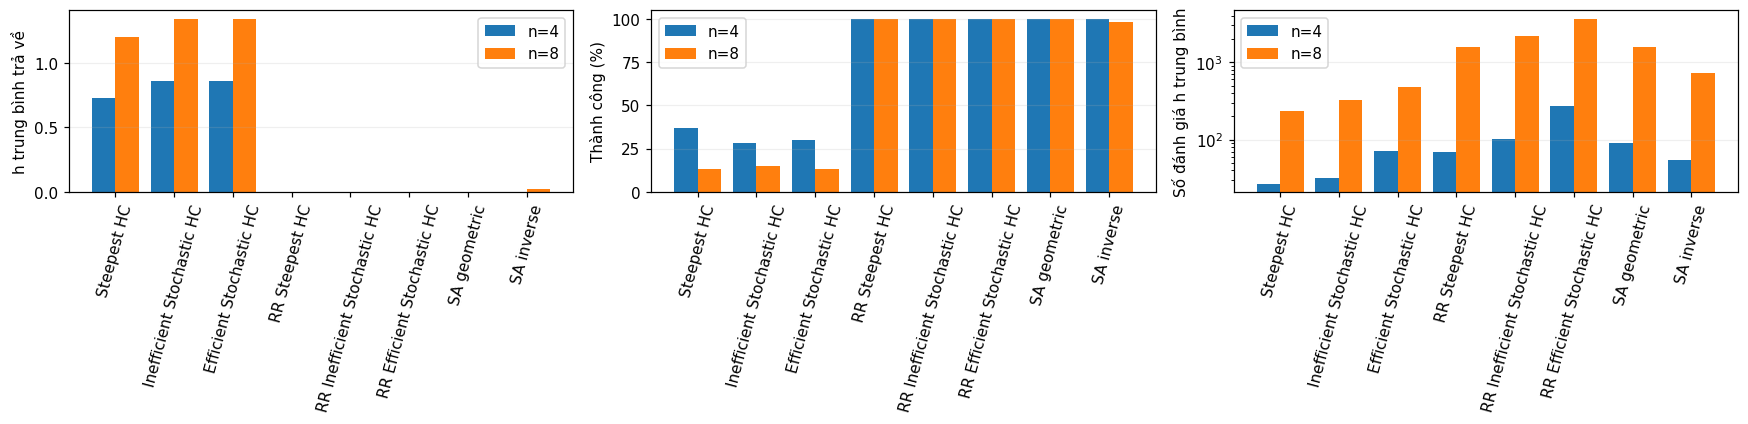

RR: thành công và chi phí được tính trên 100 lượt độc lập, mỗi lượt tối đa 100 restart.


,n,algorithm,runs,success_pct,mean_restarts,mean_evaluations,mean_seconds
2,4,RR Efficient Stochastic HC,100,100.0,2.60,268.32,0.0027
3,4,RR Inefficient Stochastic HC,100,100.0,2.27,102.87,0.0009
4,4,RR Steepest HC,100,100.0,1.53,68.41,0.0006
10,8,RR Efficient Stochastic HC,100,100.0,6.50,3672.35,0.0869
11,8,RR Inefficient Stochastic HC,100,100.0,5.71,2170.55,0.0428
12,8,RR Steepest HC,100,100.0,5.79,1551.27,0.0317


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
names = list(ALGORITHMS)
x = np.arange(len(names))
for offset, n in [(-0.2, 4), (0.2, 8)]:
    table = queen_summary[queen_summary['n'].eq(n)].set_index('algorithm').loc[names]
    for ax, metric in zip(axes, ['mean_h', 'success_pct', 'mean_evaluations']):
        ax.bar(x + offset, table[metric], width=0.4, label=f'n={n}')
for ax, label in zip(axes, ['h trung bình trả về', 'Thành công (%)', 'Số đánh giá h trung bình']):
    ax.set(ylabel=label, xticks=x, xticklabels=names)
    ax.tick_params(axis='x', labelrotation=75)
    ax.grid(axis='y', alpha=0.2)
    ax.legend()
axes[2].set_yscale('log')
plt.tight_layout()
plt.show()
print('RR: thành công và chi phí được tính trên 100 lượt độc lập, mỗi lượt tối đa 100 restart.')
display(queen_summary[queen_summary['algorithm'].str.startswith('RR ')][
    ['n', 'algorithm', 'runs', 'success_pct', 'mean_restarts', 'mean_evaluations', 'mean_seconds']].round(4))

### Hội tụ tại n = 8

Mọi thuật toán bắt đầu từ cùng `demo8`, seed tìm kiếm 2026. Trục x ghi đúng đơn vị:
HC quét đủ dùng lượt quét; first-choice/SA dùng đề xuất; RR dùng chỉ số trạng thái ghép qua các lượt,
đường dọc đánh dấu restart. Đường ngang cuối HC thể hiện bị kẹt; SA có thể tăng h trong lúc
đường “tốt nhất” không tăng. Khác đơn vị trục x nên không suy tốc độ máy từ độ dốc các đường này.

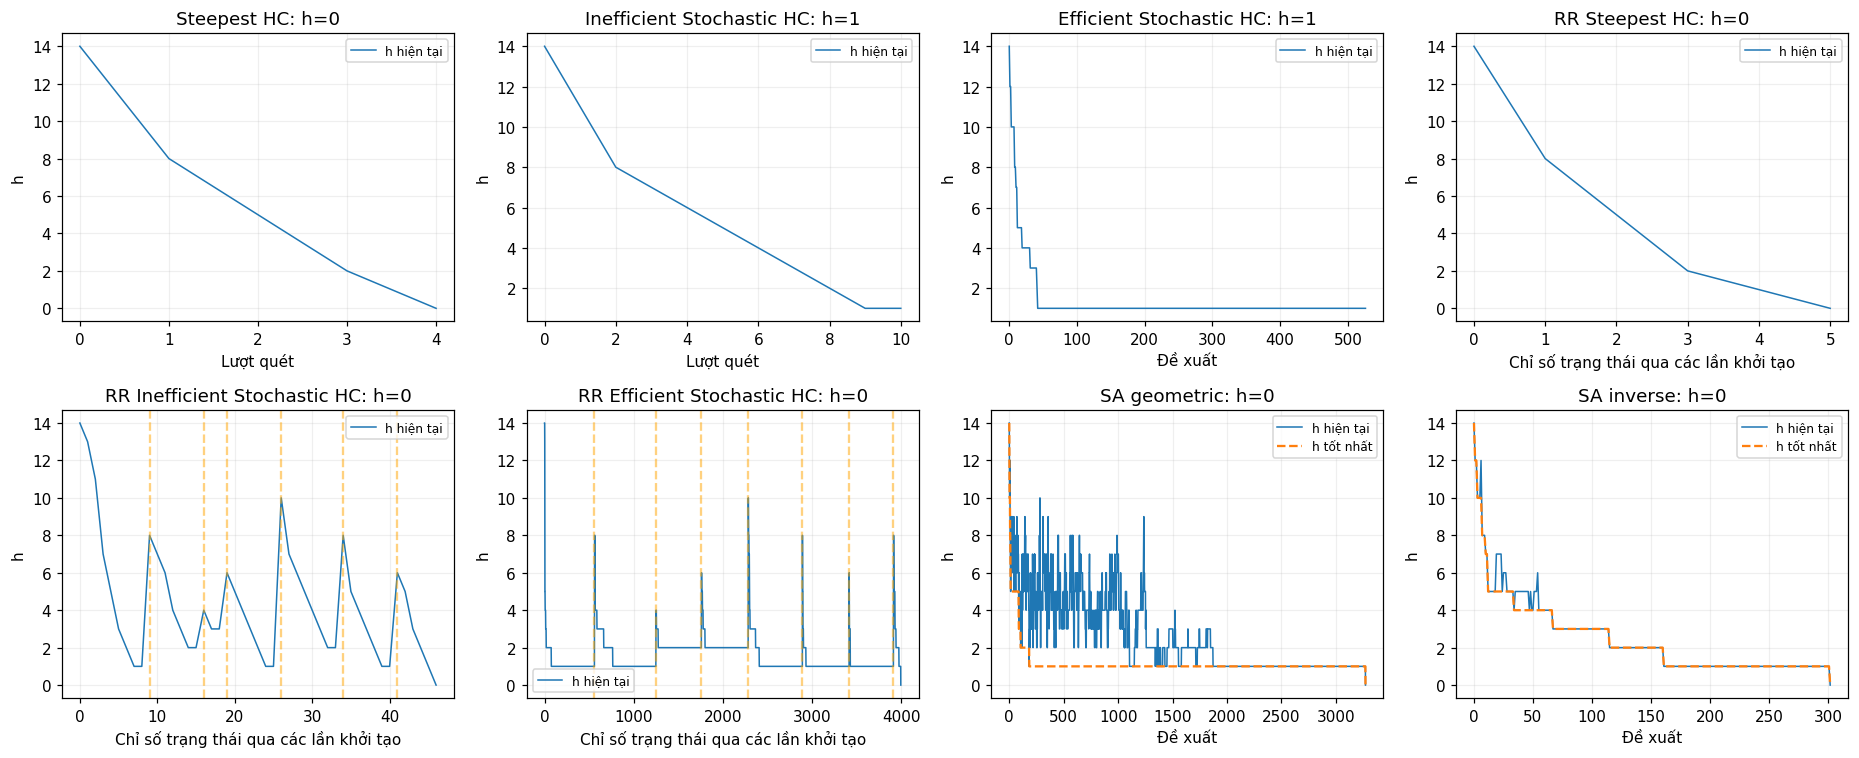

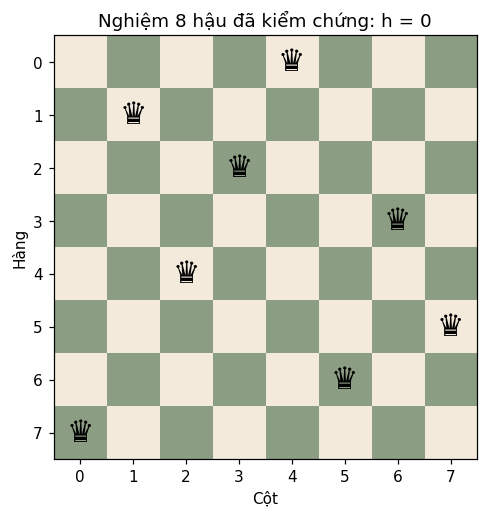

In [9]:
representatives = {**hc_demo, **rr_demo, **sa_demo}
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (name, result) in zip(axes.flat, representatives.items()):
    ax.plot(result['history'], linewidth=1, label='h hiện tại')
    if 'best_history' in result:
        ax.plot(result['best_history'], '--', label='h tốt nhất')
    for location in result.get('restart_at', []):
        ax.axvline(location, color='orange', alpha=0.5, linestyle='--')
    xlabel = 'Lượt quét' if name in ['Steepest HC', 'Inefficient Stochastic HC'] else 'Đề xuất'
    if name.startswith('RR '):
        xlabel = 'Chỉ số trạng thái qua các lần khởi tạo'
    ax.set(title=f'{name}: h={result["h"]}', xlabel=xlabel, ylabel='h')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
solution8 = rr_demo['RR Steepest HC']['board']
assert conflicts(solution8) == 0
show_board(solution8, title='Nghiệm 8 hậu đã kiểm chứng: h = 0')
plt.show()

### Khả năng mở rộng và ước lượng thực nghiệm

Đo Steepest và Efficient Stochastic tại $n=4,8,12,16,20$, **100 bàn cờ phân biệt mỗi n**,
seed `5100+n`; cùng bàn cờ và seed tìm kiếm cho hai thuật toán. Giữ nguyên tiêu chí dừng.
Vẽ log-log rồi hồi quy $\log\overline{T}=a+b\log n$ để mô tả $\overline{T}\approx e^a n^b$.
Đây là ước lượng $O(n^b)$ **trên dải đo**, không phải chứng minh Big-O khi n tiến tới vô hạn.

Trong cài đặt này, tính h tốn $O(n)$; một lượt quét Steepest có $n(n-1)$ ứng viên nên
tốn $O(n^3)$, còn một đề xuất first-choice tốn $O(n)$. Tổng thời gian còn phụ thuộc số lượt
quét/đề xuất và điều kiện dừng; thời gian nhanh nhưng thường chưa có nghiệm không đồng nghĩa giải tốt hơn.

,n,algorithm,runs,mean_seconds,median_seconds,mean_h,success_pct,mean_evaluations
0,4,Efficient Stochastic HC,100,0.00158,0.00099,0.73,38.0,64.57
1,4,Steepest HC,100,0.00060,0.00038,0.58,46.0,27.16
2,8,Efficient Stochastic HC,100,0.01179,0.00846,1.37,12.0,485.98
3,8,Steepest HC,100,0.00434,0.00292,1.31,14.0,225.56
4,12,Efficient Stochastic HC,100,0.04487,0.03473,1.91,4.0,1346.61
5,12,Steepest HC,100,0.02164,0.01521,2.02,2.0,741.52
6,16,Efficient Stochastic HC,100,0.11698,0.09414,2.09,4.0,2676.14
7,16,Steepest HC,100,0.06705,0.05266,2.06,7.0,1784.20
8,20,Efficient Stochastic HC,100,0.22268,0.17373,2.57,0.0,4605.70
9,20,Steepest HC,100,0.15413,0.13109,2.46,0.0,3531.20


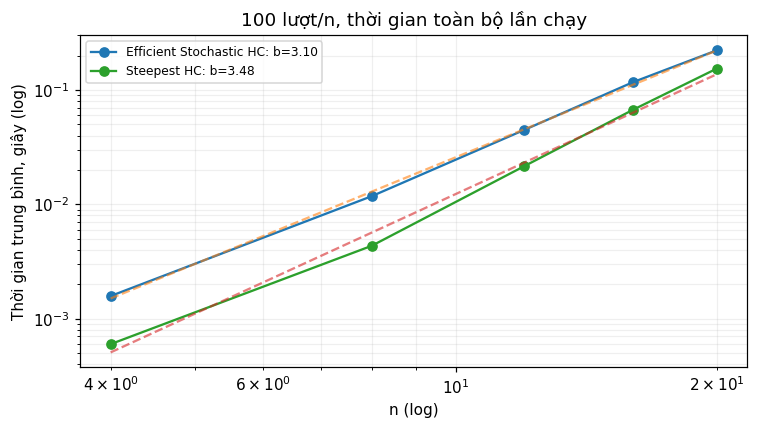

,algorithm,empirical_exponent
0,Efficient Stochastic HC,3.103
1,Steepest HC,3.480


In [10]:
scale_rows = []
for n in [4, 8, 12, 16, 20]:
    for trial, initial in enumerate(make_starts(n, RUNS, 5100 + n)):
        for name in ['Steepest HC', 'Efficient Stochastic HC']:
            result = hill_climb(initial, hc_variants[name], seed=200_000 * n + trial)
            scale_rows.append(dict(n=n, trial=trial, search_seed=200_000 * n + trial,
                                   initial_board=json.dumps(initial), algorithm=name,
                                   h=result['h'], seconds=result['seconds'],
                                   evaluations=result['evaluations'], status=result['status']))
scale_raw = pd.DataFrame(scale_rows)
scale_summary = scale_raw.groupby(['n', 'algorithm'], as_index=False).agg(
    runs=('h', 'size'), mean_seconds=('seconds', 'mean'), median_seconds=('seconds', 'median'),
    mean_h=('h', 'mean'), success_pct=('h', lambda s: 100 * s.eq(0).mean()),
    mean_evaluations=('evaluations', 'mean'))
display(scale_summary.round(5))
fig, ax = plt.subplots(figsize=(7, 4))
complexity_rows = []
for name, group in scale_summary.groupby('algorithm'):
    slope, intercept = np.polyfit(np.log(group['n']), np.log(group['mean_seconds']), 1)
    complexity_rows.append(dict(algorithm=name, empirical_exponent=slope))
    ax.loglog(group['n'], group['mean_seconds'], 'o-', label=f'{name}: b={slope:.2f}')
    ax.loglog(group['n'], np.exp(intercept) * group['n'] ** slope, '--', alpha=0.6)
ax.set(xlabel='n (log)', ylabel='Thời gian trung bình, giây (log)', title='100 lượt/n, thời gian toàn bộ lần chạy')
ax.legend(fontsize=8)
ax.grid(which='both', alpha=0.2)
plt.tight_layout()
plt.show()
display(pd.DataFrame(complexity_rows).round(3))

## Advanced task. Thay toán tử di chuyển

Đã cài trong `propose()`:

- `single`: đối chứng, chuyển một hậu tới hàng khác bất kỳ.
- `single_step`: chuyển một hậu lên/xuống đúng một ô, không đi vòng qua biên.
- `swap`: đổi hàng của hai hậu ở hai cột khác nhau; nếu cùng hàng thì trạng thái không đổi.
- `dual`: chọn hai cột khác nhau, đồng thời đổi cả hai hậu sang hàng khác hàng cũ.
- `adaptive`: 60% tập trung vào hậu đang có nhiều xung đột nhất, 40% lấy đều nước đi đơn.

Dùng **Efficient Stochastic**, $n=8,12$, **100 bàn cờ phân biệt mỗi n**, cùng tập khởi tạo và seed
tìm kiếm cho 5 toán tử, tối đa **5.000 đề xuất**. Patience được tính theo kích thước tập nước đi
(với adaptive dùng cận xác suất từ nhánh lấy đều 40%). Với dual, patience có thể lớn hơn
5.000, vì vậy dừng ngân sách không cho phép khẳng định đã lấy mẫu gần hết láng giềng.

Swap bảo toàn tập đa trị số hàng; nếu bàn cờ ban đầu có hai hậu cùng hàng thì chỉ swap
không thể xóa xung đột hàng. Đây là hạn chế không gian trạng thái, cần nêu khi đọc tỷ lệ thành công.
Hội tụ dùng **h hiện tại trung bình trên cả 100 lượt**, giữ nguyên h cuối sau khi dừng sớm để
không loại các lượt đã giải hoặc thất bại khỏi đường trung bình. Thời gian đạt nghiệm chỉ tính
các lượt h=0; nhóm không thành công có giá trị thiếu, không gán 0 giây.

,n,operator,runs,mean_h,success_pct,mean_seconds,mean_evaluations,limited,successes,mean_time_to_solution
0,8,adaptive,100,1.15,16.0,0.0331,1052.01,0,16,0.0011
1,8,dual,100,0.79,23.0,0.0749,4245.45,77,23,0.0283
2,8,single,100,1.23,15.0,0.0062,487.54,0,15,0.0012
3,8,single_step,100,3.41,0.0,0.0021,142.65,0,0,NaN
4,8,swap,100,4.42,0.0,0.0043,244.43,0,0,NaN
5,12,adaptive,100,1.81,5.0,0.2306,3058.79,0,5,0.0161
6,12,dual,100,1.05,10.0,0.1734,4809.41,90,10,0.1136
7,12,single,100,1.96,3.0,0.0372,1377.90,0,3,0.0114
8,12,single_step,100,5.54,0.0,0.0067,224.69,0,0,NaN
9,12,swap,100,6.56,0.0,0.0225,652.52,0,0,NaN


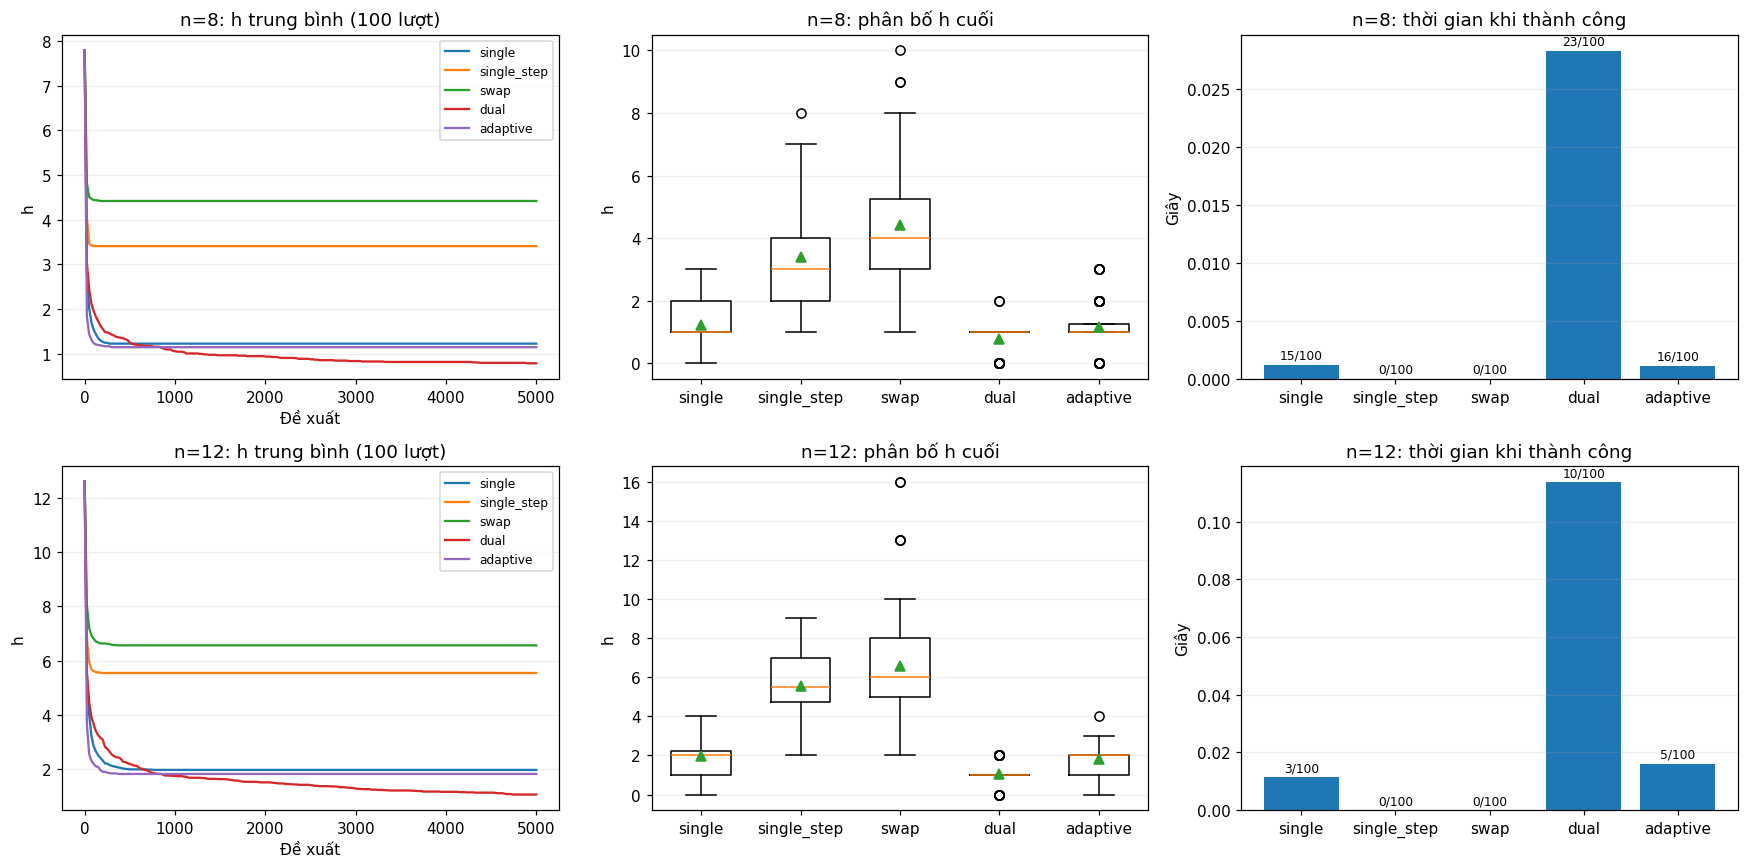

In [11]:
OPERATORS = ['single', 'single_step', 'swap', 'dual', 'adaptive']
GRID = np.arange(0, 5001, 25)
operator_rows, trajectory_rows = [], []
for n in [8, 12]:
    starts = make_starts(n, RUNS, 6100 + n)
    for trial, initial in enumerate(starts):
        for operator in OPERATORS:
            seed = 300_000 * n + trial
            result = hill_climb(initial, 'efficient', seed=seed, operator=operator,
                                max_iterations=5000, record_history=True)
            assert result['h'] == conflicts(result['board'])
            history = np.asarray(result['history'])
            sampled = history[np.minimum(GRID, len(history) - 1)]
            trajectory_rows.extend(dict(n=n, operator=operator, trial=trial,
                                        proposal=int(step), h=int(h))
                                   for step, h in zip(GRID, sampled))
            operator_rows.append(dict(n=n, trial=trial, search_seed=seed, operator=operator,
                                      initial_board=json.dumps(initial),
                                      **{key: result[key] for key in ['h', 'seconds', 'status',
                                          'stop_reason', 'evaluations', 'iterations', 'moves', 'patience']}))
operator_raw = pd.DataFrame(operator_rows)
operator_summary = operator_raw.groupby(['n', 'operator'], as_index=False).agg(
    runs=('h', 'size'), mean_h=('h', 'mean'), success_pct=('h', lambda s: 100 * s.eq(0).mean()),
    mean_seconds=('seconds', 'mean'), mean_evaluations=('evaluations', 'mean'),
    limited=('status', lambda s: s.eq('budget').sum()))
operator_success = operator_raw[operator_raw['h'].eq(0)].groupby(['n', 'operator'], as_index=False).agg(
    successes=('h', 'size'), mean_time_to_solution=('seconds', 'mean'))
operator_summary = operator_summary.merge(operator_success, on=['n', 'operator'], how='left')
operator_summary['successes'] = operator_summary['successes'].fillna(0).astype(int)
trajectory_summary = pd.DataFrame(trajectory_rows).groupby(
    ['n', 'operator', 'proposal'], as_index=False).agg(mean_h=('h', 'mean'))
display(operator_summary.round(4))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for row, n in enumerate([8, 12]):
    for index, operator in enumerate(OPERATORS):
        curve = trajectory_summary[(trajectory_summary['n'] == n) &
                                   (trajectory_summary['operator'] == operator)]
        axes[row, 0].plot(curve['proposal'], curve['mean_h'], label=operator)
        final = operator_raw[(operator_raw['n'] == n) & (operator_raw['operator'] == operator)]['h']
        # Lệch nhẹ vị trí để nhìn được các phân bố trùng nhau.
        axes[row, 1].boxplot([final], positions=[index], widths=0.6, showmeans=True)
    group = operator_summary[operator_summary['n'].eq(n)].set_index('operator').loc[OPERATORS]
    axes[row, 2].bar(range(len(OPERATORS)), group['mean_time_to_solution'])
    for index, record in enumerate(group.itertuples()):
        y = record.mean_time_to_solution
        axes[row, 2].annotate(f'{record.successes}/100',
                              (index, y if np.isfinite(y) else 0),
                              ha='center', xytext=(0, 4), textcoords='offset points', fontsize=8)
    axes[row, 0].set(title=f'n={n}: h trung bình (100 lượt)', xlabel='Đề xuất', ylabel='h')
    axes[row, 0].legend(fontsize=8)
    axes[row, 1].set(title=f'n={n}: phân bố h cuối', ylabel='h',
                     xticks=range(len(OPERATORS)), xticklabels=OPERATORS)
    axes[row, 2].set(title=f'n={n}: thời gian khi thành công', ylabel='Giây',
                     xticks=range(len(OPERATORS)), xticklabels=OPERATORS)
    for ax in axes[row]:
        ax.grid(axis='y', alpha=0.2)
plt.tight_layout()
plt.show()

## Nhận xét thực nghiệm và trả lời thảo luận

Đoạn sau lấy trực tiếp số liệu đã chạy. Tỷ lệ thành công là số lượt h=0 chia tổng lượt;
chi phí trung bình chính tính trên cả thành công và thất bại. Bảng thời gian đạt nghiệm ở Advanced
chỉ tính trên các lượt thành công nên phải đọc cùng số lần thành công, tránh thiên lệch chọn mẫu.

In [12]:
lines = []
for n in [4, 8]:
    table = queen_summary[queen_summary['n'].eq(n)].set_index('algorithm')
    lines.append(f'- **n={n}:** Steepest / Inefficient / Efficient HC đạt '
                 + ' / '.join(f'{table.loc[name, "success_pct"]:.0f}%' for name in hc_variants)
                 + ' nghiệm hợp lệ; số đánh giá h trung bình lần lượt '
                 + ' / '.join(f'{table.loc[name, "mean_evaluations"]:.1f}' for name in hc_variants) + '.')
    for name in [name for name in ALGORITHMS if name.startswith('RR ')]:
        r = table.loc[name]
        lines.append(f'- **{name}, n={n}:** thành công {r["success_pct"]:.0f}%, '
                     f'trung bình {r["mean_restarts"]:.2f} restart, '
                     f'{r["mean_evaluations"]:.1f} đánh giá h mỗi lượt độc lập.')
    for name in ['SA geometric', 'SA inverse']:
        r = table.loc[name]
        lines.append(f'- **{name}, n={n}:** thành công {r["success_pct"]:.0f}%, '
                     f'h tốt nhất trung bình {r["mean_h"]:.3f}, '
                     f'h cuối trung bình {r["mean_final_h"]:.3f}, '
                     f'{r["mean_seconds"] * 1000:.2f} ms/lượt.')
for n in [4, 8]:
    for name in hc_variants:
        group = queen_raw[(queen_raw['n'] == n) & (queen_raw['algorithm'] == name)]
        reasons = group['stop_reason'].value_counts()
        lines.append(f'- **Mắc kẹt, {name}, n={n}:** '
                     f'{reasons.get("plateau", 0)} lượt dừng tại plateau, '
                     f'{reasons.get("strict_local_minimum", 0)} cực tiểu nghiêm ngặt, '
                     f'{reasons.get("probabilistic_stopping", 0)} dừng sau chuỗi lấy mẫu không cải thiện; '
                     f'{reasons.get("proposal_limit", 0)} hết giới hạn đề xuất. '
                     'First-choice chưa chứng minh đã xét hết láng giềng.')
    table = queen_summary[queen_summary['n'].eq(n)].set_index('algorithm')
    geo, inv = table.loc['SA geometric'], table.loc['SA inverse']
    faster = 'geometric' if geo['mean_seconds'] < inv['mean_seconds'] else 'inverse'
    lines.append(f'- **So sánh lịch nhiệt, n={n}:** {faster} có thời gian trung bình thấp hơn; '
                 f'geometric đạt {geo["success_pct"]:.0f}% và inverse đạt {inv["success_pct"]:.0f}% nghiệm. '
                 'Inverse giảm nhiệt nhanh đầu quá trình, giảm dao động nhưng có thể kẹt sớm; '
                 'geometric duy trì khả năng nhận bước xấu lâu hơn. '
                 'Đây là đánh đổi tốc độ/tỷ lệ thành công trên đúng 100 bàn cờ đã đo, '
                 'không bảo đảm một lịch luôn tốt hơn cho mọi đầu vào.')
for row in complexity_rows:
    lines.append(f'- **Mở rộng, {row["algorithm"]}:** ước lượng T ∝ '
                 f'n^{row["empirical_exponent"]:.2f} trên n=4..20 với tiêu chí dừng đã nêu.')
largest_n = scale_summary['n'].max()
largest = scale_summary[scale_summary['n'].eq(largest_n)]
fastest = largest.loc[largest['mean_seconds'].idxmin()]
smallest_exponent = min(complexity_rows, key=lambda row: row['empirical_exponent'])
lines.append(f'- **So sánh mở rộng:** tại n={largest_n}, {fastest["algorithm"]} có thời gian '
             f'trung bình thấp nhất ({fastest["mean_seconds"] * 1000:.2f} ms); '
             f'{smallest_exponent["algorithm"]} có số mũ tăng thực nghiệm nhỏ nhất '
             f'({smallest_exponent["empirical_exponent"]:.2f}). '
             'First-choice tiết kiệm một lượt quét nhưng chi phí chờ đủ mẫu để dừng có thể lớn. '
             f'Tỷ lệ thành công tại n={largest_n}: '
             + '; '.join(f'{r.algorithm} = {r.success_pct:.0f}%' for r in largest.itertuples())
             + '. Vì thế chưa thể chọn một thuật toán giải được bài lớn tốt nhất chỉ từ thời gian dừng.')
for n in [8, 12]:
    group = operator_summary[operator_summary['n'].eq(n)]
    best = group.sort_values(['success_pct', 'mean_h'], ascending=[False, True]).iloc[0]
    lines.append(f'- **Toán tử tại n={n}:** {best["operator"]} đứng đầu theo tỷ lệ thành công '
                 f'({best["success_pct"]:.0f}%), rồi theo h trung bình '
                 f'({best["mean_h"]:.3f}); đây là kết quả trong ngân sách 5.000 đề xuất.')
display(Markdown(chr(10).join(lines)))

- **n=4:** Steepest / Inefficient / Efficient HC đạt 37% / 28% / 30% nghiệm hợp lệ; số đánh giá h trung bình lần lượt 26.9 / 32.2 / 71.0.
- **RR Steepest HC, n=4:** thành công 100%, trung bình 1.53 restart, 68.4 đánh giá h mỗi lượt độc lập.
- **RR Inefficient Stochastic HC, n=4:** thành công 100%, trung bình 2.27 restart, 102.9 đánh giá h mỗi lượt độc lập.
- **RR Efficient Stochastic HC, n=4:** thành công 100%, trung bình 2.60 restart, 268.3 đánh giá h mỗi lượt độc lập.
- **SA geometric, n=4:** thành công 100%, h tốt nhất trung bình 0.000, h cuối trung bình 0.000, 1.15 ms/lượt.
- **SA inverse, n=4:** thành công 100%, h tốt nhất trung bình 0.000, h cuối trung bình 0.000, 0.66 ms/lượt.
- **n=8:** Steepest / Inefficient / Efficient HC đạt 13% / 15% / 13% nghiệm hợp lệ; số đánh giá h trung bình lần lượt 236.2 / 327.5 / 479.1.
- **RR Steepest HC, n=8:** thành công 100%, trung bình 5.79 restart, 1551.3 đánh giá h mỗi lượt độc lập.
- **RR Inefficient Stochastic HC, n=8:** thành công 100%, trung bình 5.71 restart, 2170.6 đánh giá h mỗi lượt độc lập.
- **RR Efficient Stochastic HC, n=8:** thành công 100%, trung bình 6.50 restart, 3672.3 đánh giá h mỗi lượt độc lập.
- **SA geometric, n=8:** thành công 100%, h tốt nhất trung bình 0.000, h cuối trung bình 0.000, 43.02 ms/lượt.
- **SA inverse, n=8:** thành công 98%, h tốt nhất trung bình 0.020, h cuối trung bình 0.020, 21.76 ms/lượt.
- **Mắc kẹt, Steepest HC, n=4:** 63 lượt dừng tại plateau, 0 cực tiểu nghiêm ngặt, 0 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **Mắc kẹt, Inefficient Stochastic HC, n=4:** 72 lượt dừng tại plateau, 0 cực tiểu nghiêm ngặt, 0 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **Mắc kẹt, Efficient Stochastic HC, n=4:** 0 lượt dừng tại plateau, 0 cực tiểu nghiêm ngặt, 70 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **So sánh lịch nhiệt, n=4:** inverse có thời gian trung bình thấp hơn; geometric đạt 100% và inverse đạt 100% nghiệm. Inverse giảm nhiệt nhanh đầu quá trình, giảm dao động nhưng có thể kẹt sớm; geometric duy trì khả năng nhận bước xấu lâu hơn. Đây là đánh đổi tốc độ/tỷ lệ thành công trên đúng 100 bàn cờ đã đo, không bảo đảm một lịch luôn tốt hơn cho mọi đầu vào.
- **Mắc kẹt, Steepest HC, n=8:** 86 lượt dừng tại plateau, 1 cực tiểu nghiêm ngặt, 0 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **Mắc kẹt, Inefficient Stochastic HC, n=8:** 85 lượt dừng tại plateau, 0 cực tiểu nghiêm ngặt, 0 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **Mắc kẹt, Efficient Stochastic HC, n=8:** 0 lượt dừng tại plateau, 0 cực tiểu nghiêm ngặt, 87 dừng sau chuỗi lấy mẫu không cải thiện; 0 hết giới hạn đề xuất. First-choice chưa chứng minh đã xét hết láng giềng.
- **So sánh lịch nhiệt, n=8:** inverse có thời gian trung bình thấp hơn; geometric đạt 100% và inverse đạt 98% nghiệm. Inverse giảm nhiệt nhanh đầu quá trình, giảm dao động nhưng có thể kẹt sớm; geometric duy trì khả năng nhận bước xấu lâu hơn. Đây là đánh đổi tốc độ/tỷ lệ thành công trên đúng 100 bàn cờ đã đo, không bảo đảm một lịch luôn tốt hơn cho mọi đầu vào.
- **Mở rộng, Efficient Stochastic HC:** ước lượng T ∝ n^3.10 trên n=4..20 với tiêu chí dừng đã nêu.
- **Mở rộng, Steepest HC:** ước lượng T ∝ n^3.48 trên n=4..20 với tiêu chí dừng đã nêu.
- **So sánh mở rộng:** tại n=20, Steepest HC có thời gian trung bình thấp nhất (154.13 ms); Efficient Stochastic HC có số mũ tăng thực nghiệm nhỏ nhất (3.10). First-choice tiết kiệm một lượt quét nhưng chi phí chờ đủ mẫu để dừng có thể lớn. Tỷ lệ thành công tại n=20: Efficient Stochastic HC = 0%; Steepest HC = 0%. Vì thế chưa thể chọn một thuật toán giải được bài lớn tốt nhất chỉ từ thời gian dừng.
- **Toán tử tại n=8:** dual đứng đầu theo tỷ lệ thành công (23%), rồi theo h trung bình (0.790); đây là kết quả trong ngân sách 5.000 đề xuất.
- **Toán tử tại n=12:** dual đứng đầu theo tỷ lệ thành công (10%), rồi theo h trung bình (1.050); đây là kết quả trong ngân sách 5.000 đề xuất.

**1–3. Liên hệ với CSP.** Phép gán đầy đủ chưa chắc là nghiệm: phải kiểm tra miền và mọi ràng buộc.
MRV/FC giảm nhánh qua chọn biến khó và phát hiện miền rỗng; chi phí quản lý miền có thể lấn át
lợi ích trên bài nhỏ. Tô 3 màu có thể thất bại vì vô nghiệm hoặc hết ngân sách; chỉ Backtracking
duyệt hết cây mới chứng minh vô nghiệm, còn Min-Conflicts không có kết luận đó.

**4. Cực trị/plateau và cách xử lý.** HC chỉ nhận h giảm nên có thể dừng khi h>0.
RR đổi hẳn điểm bắt đầu, phải trả chi phí tìm lại; SA giữ một quỹ đạo, nhận cả bước ngang và
bước tăng h theo nhiệt độ để thoát vùng kẹt. Cả hai vẫn có thể thất bại trong ngân sách hữu hạn.
Các đường hội tụ minh họa thể hiện khác biệt này, không bảo đảm mọi seed đều giống lượt minh họa.

**5. Số đánh giá láng giềng.** Steepest và Inefficient Stochastic đều cần $n(n-1)$ lần đánh giá
mỗi lượt quyết định. First-choice chỉ cần một lần mỗi đề xuất, nhưng có thể phải đề xuất nhiều
lần mới gặp một cải thiện và phải lấy thêm mẫu để nhận biết mắc kẹt. Vì vậy “efficient” nói về
chi phí mỗi đề xuất; tổng thời gian và chất lượng phải đối chiếu bằng thực nghiệm.

**6. Nhiều lượt và điều kiện so sánh.** Một seed may mắn có thể cho kết luận sai. Dùng 100 bàn cờ
phân biệt cho mỗi cấu hình, ghép cùng tập đầu vào giữa thuật toán và lưu seed giúp so sánh công bằng
hơn. Seed cố định không xóa nhiễu thời gian hệ thống; các tỷ lệ vẫn chỉ ước lượng trên tập đã đo.
Khi ngân sách khác nhau phải báo rõ, khi tính trung bình phải nêu có gồm thất bại hay chỉ thành công.

**Toán tử và khả năng mở rộng.** Single-step chỉ đổi nhỏ nên có thể bỏ lỡ cải thiện xa;
dual thay hai hậu có thể vượt vùng mà đổi một hậu không cải thiện nhưng có tập nước đi rất lớn.
Swap chỉ phù hợp nếu tập hàng ban đầu cho phép nghiệm; nó không sửa được lặp hàng vì bảo toàn
đa tập hàng. Adaptive tập trung vào nguồn xung đột, song tính mức xung đột từng hậu làm tăng chi phí
mỗi đề xuất. Chọn toán tử phải cân đối tỷ lệ thành công, h cuối và thời gian trong đúng bảng ở trên.

Một lượt Steepest thường giảm h nhanh theo số lượt quét; stochastic có tiến bộ không đều;
first-choice có thể có nhiều đề xuất bị bác bỏ, còn SA có giai đoạn dao động trước khi giảm nhiệt.
Số mũ hồi quy phản ánh cả cài đặt và cách dừng; không coi nó là định lý độ phức tạp của thuật toán.

## Lưu số liệu và bảng tổng hợp nộp bài

Lưu tập đầu vào/seed, dữ liệu từng lượt, bảng tổng hợp, đường hội tụ trung bình, tham số và phiên bản.
Nếu đã chạy notebook tô màu trước, tạo thêm bảng chung cho cả hai bài toán và báo cáo Markdown.

In [13]:
lab_dir = Path.cwd()
if (lab_dir / 'weekly assignments' / 'lab04 - csp').is_dir():
    lab_dir = lab_dir / 'weekly assignments' / 'lab04 - csp'
result_dir = lab_dir / 'results'
result_dir.mkdir(exist_ok=True)
tables = {
    'queens_initial_boards.csv': pd.DataFrame(initial_rows),
    'queens_benchmark_raw.csv': queen_raw,
    'queens_benchmark_summary.csv': queen_summary,
    'queens_scaling_raw.csv': scale_raw,
    'queens_scaling_summary.csv': scale_summary,
    'queens_empirical_complexity.csv': pd.DataFrame(complexity_rows),
    'queens_operators_raw.csv': operator_raw,
    'queens_operators_summary.csv': operator_summary,
    'queens_operators_trajectories.csv': trajectory_summary,
}
for filename, frame in tables.items():
    frame.to_csv(result_dir / filename, index=False, encoding='utf-8-sig')
settings = {
    'runs_per_configuration': RUNS, 'benchmark_n': [4, 8], 'benchmark_board_seed': '4100+n',
    'benchmark_search_seed': '100000*n+trial',
    'scaling_n': [4, 8, 12, 16, 20], 'scaling_board_seed': '5100+n',
    'scaling_search_seed': '200000*n+trial',
    'operator_n': [8, 12], 'operator_board_seed': '6100+n',
    'operator_search_seed': '300000*n+trial',
    'hc_max_iterations': 10_000, 'epsilon_per_stagnant_state': 0.01,
    'rr_max_restarts': 100, 'rr_max_starts': 101,
    'sa_max_steps': 5000, 'sa_t0': 2.0, 'sa_tend': 0.01,
    'sa_schedules': ['geometric', 'inverse'], 'operators_max_proposals': 5000,
    'operators': OPERATORS, 'adaptive_uniform_probability': 0.4,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__,
                 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
    'timing_scope': 'solver including internal initialization/restarts; excludes dataset generation and rendering',
}
(result_dir / 'queens_settings.json').write_text(json.dumps(settings, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(queen_raw) == 2 * RUNS * len(ALGORITHMS)
assert len(scale_raw) == 5 * RUNS * 2
assert len(operator_raw) == 2 * RUNS * len(OPERATORS)
assert queen_summary['runs'].eq(100).all() and operator_summary['runs'].eq(100).all()

graph_summary_file = result_dir / 'benchmark_summary.csv'
if graph_summary_file.exists():
    graph_summary = pd.read_csv(graph_summary_file)
    combined_rows = []
    for row in graph_summary.itertuples():
        combined_rows.append(dict(problem='Graph coloring', n=row.n, algorithm=row.algorithm,
            colors=row.colors, runs=row.runs, success_pct=row.success_pct,
            mean_conflicts=row.mean_best_conflicts, mean_COUNT=row.mean_COUNT,
            mean_evaluations=np.nan, mean_steps=row.mean_steps, mean_seconds=row.mean_ms / 1000))
    for row in queen_summary.itertuples():
        combined_rows.append(dict(problem='n-Queens', n=row.n, algorithm=row.algorithm,
            colors=np.nan, runs=row.runs, success_pct=row.success_pct,
            mean_conflicts=row.mean_h, mean_COUNT=np.nan,
            mean_evaluations=row.mean_evaluations, mean_steps=row.mean_iterations,
            mean_seconds=row.mean_seconds))
    combined = pd.DataFrame(combined_rows)
    combined.to_csv(result_dir / 'lab04_combined_summary.csv', index=False, encoding='utf-8-sig')
    report = ['# Báo cáo Lab 04 — CSP và n-Queens',
        '', '**Team: Quý - Phúc - Tri - Khoa**',
        '', '## Sản phẩm', '',
        '- [Tô màu: notebook](CSP_graph_coloring_example.ipynb) và [HTML](CSP_graph_coloring_example.html).',
        '- [n-Queens: notebook](n_queens.ipynb) và [HTML](n_queens.html).',
        '- [Bảng chung](results/lab04_combined_summary.csv), [kết quả chi tiết](results/).',
        '', '## Thiết kế và kiểm chứng', '',
        'Tô màu: 25 đồ thị (5 seed/kích thước 10,20,40,80,160), 3/4 màu, 6 cấu hình; '
        '300 lần chạy chính. Thử thêm 320/640 đỉnh, 3 seed/kích thước và 2 thuật toán. '
        'Kiểm chứng 640 lượt Backtracking với vét cạn, hoàn tác miền và các trường hợp MC.',
        '', 'n-Queens: 100 bàn cờ khởi tạo phân biệt/cấu hình, n=4/8, 8 cấu hình '
        '(1.600 lượt); mở rộng n=4,8,12,16,20 với 2 thuật toán (1.000 lượt); '
        '5 toán tử tại n=8/12 (1.000 lượt). Hàm mục tiêu đối chiếu 256 bàn cờ 4 hậu; '
        'kiểm thử tính đơn điệu, điểm dừng, restart, SA và toán tử.',
        '', 'Ngân sách, seed và phiên bản nằm trong results/settings.json và results/queens_settings.json. '
        'Thời gian tính trong solver, không gồm sinh dữ liệu/vẽ. Các bảng chính tính trung bình '
        'trên mọi lượt, kể cả thất bại; bảng thời gian đạt nghiệm chỉ tính lần thành công.',
        '', '## Bảng n-Queens (100 lượt/mỗi dòng)', '',
        '| n | Thuật toán | Thời gian TB (s) | h tốt nhất TB | Thành công (%) | Đánh giá h TB | Restart TB |',
        '|---|---|---|---|---|---|---|']
    # Bảng tô màu theo mẫu mục 4.2 PDF, cùng dữ liệu với notebook/CSV.
    queen_header = report.index('## Bảng n-Queens (100 lượt/mỗi dòng)')
    graph_report = ['## Bảng tô màu (5 seed/mỗi dòng)', '',
        '| n | Màu | Thuật toán | Thành công (%) | COUNT TB | Bước MC TB | Thời gian TB (s) |',
        '|---|---|---|---|---|---|---|']
    def number(value):
        return '—' if pd.isna(value) else f'{value:.3f}'
    for r in graph_summary.itertuples():
        graph_report.append(f'| {r.n} | {r.colors} | {r.algorithm} | {r.success_pct:.0f} | '
                            f'{number(r.mean_COUNT)} | {number(r.mean_steps)} | {r.mean_ms / 1000:.6f} |')
    graph_report.extend(['', 'COUNT và bước MC là hai đơn vị khác nhau. Tỷ lệ thành công là '
        'tìm được nghiệm, không phải tỷ lệ kết luận được bài toán; xem notebook/CSV để phân biệt unsat/limit.', ''])
    report[queen_header:queen_header] = graph_report
    for r in queen_summary.itertuples():
        report.append(f'| {r.n} | {r.algorithm} | {r.mean_seconds:.6f} | {r.mean_h:.3f} | '
                      f'{r.success_pct:.0f} | {r.mean_evaluations:.1f} | {r.mean_restarts:.2f} |')
    report.extend(['', '## Nhận xét từ n-Queens', '', *lines,
        '', '## Cách hiểu kết quả', '',
        'Nghiệm hợp lệ cần h=0 hoặc gán đầy đủ và nhất quán. Hết ngân sách không đồng nghĩa '
        'vô nghiệm; chỉ Backtracking duyệt hết cây mới báo unsat. COUNT của tô màu là số nút '
        'đệ quy; evaluations của n-Queens là số lần đánh giá h, không phải cùng đơn vị.',
        '', 'MRV/LCV/FC có chi phí quản lý và chấm điểm; lợi ích phải đọc số liệu cùng đồ thị. '
        'HC mắc cực trị/plateau do chỉ nhận cải thiện; RR đổi điểm đầu còn SA nhận một số bước '
        'tăng h theo nhiệt độ. Tỷ lệ trên 100 lượt và số mũ log-log là thực nghiệm hữu hạn, '
        'không bảo đảm tổng quát cho mọi đầu vào.',
        '', '## Nguồn tham khảo', '',
        '- Đề TTNTNC - Lab04 - Bai toan thoa man rang buoc.pdf và hai notebook được cung cấp.',
        '- [UC Berkeley CS188: Local Search](https://inst.eecs.berkeley.edu/~cs188/textbook/csp/local-search.html): '
        'nguyên tắc chấp nhận bước của Simulated Annealing. Thông số lịch nhiệt là lựa chọn thực nghiệm của bài làm.',
        '', 'Công cụ hỗ trợ: OpenAI Codex.'])
    (lab_dir / 'BAO_CAO_LAB04.md').write_text(chr(10).join(report) + chr(10), encoding='utf-8')
    print('Đã lưu bảng chung và BAO_CAO_LAB04.md.')
else:
    print('Chạy notebook tô màu trước để bổ sung bảng tổng hợp chung.')
print('Hoàn tất bài 5–8, Task 1–6 và Advanced task; lưu 9 bảng n-Queens cùng cấu hình.')

Đã lưu bảng chung và BAO_CAO_LAB04.md.
Hoàn tất bài 5–8, Task 1–6 và Advanced task; lưu 9 bảng n-Queens cùng cấu hình.
